# Linear Regression: Next-Game Points Prediction

This notebook trains a Linear Regression model to predict how many points a player scores in a game, using only information available **before** tip-off. It is scored on the same test games as the baselines in `ml/EDA/prediction_baseline.ipynb`, so the numbers can be compared directly.

**Target definition:** every feature in a row is built from the player's *earlier* games (`shift(1)`), so predicting that row's `points` is a next-game prediction. A game's own stats never feed its features.

The notebook runs on the small sample dataset by default. Every dataset-specific setting is in the **Config** cell, so a larger dataset can be used without changing any other cell.

## Config

- `POINTS_DATA_PATH` (environment variable): set it to use a different feature CSV. If it is not set, the notebook looks for `data/sample/sample_player_game_logs_features.csv` from this folder or any parent folder.
- `BASE_FEATURES`: the points averages from `data/processing/points_features.py`. Rows without them (a player's first game) are dropped, the same rule the baseline notebook uses.
- `CONTEXT_FEATURES`: extra pre-game context from `data/processing/modeling_features.py` (`is_home` from the matchup, and `recent_minutes_avg` over the prior 5 games).
- `SAVE_MODEL`: off by default so running the notebook does not create files.

In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Make the repo root importable so the shared feature code can be used here.
REPO_ROOT = next(
    (root for root in (Path.cwd(), *Path.cwd().parents) if (root / 'data' / 'processing' / 'points_features.py').exists()),
    None,
)
assert REPO_ROOT is not None, 'Could not find the repo root (data/processing/points_features.py)'
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from data.processing.modeling_features import add_modeling_context
from data.processing.points_features import FEATURE_COLS, time_split

# Dataset: override with the POINTS_DATA_PATH environment variable for larger datasets.
DATA_RELATIVE_PATH = Path('data') / 'sample' / 'sample_player_game_logs_features.csv'
DATA_PATH = Path(os.environ.get('POINTS_DATA_PATH', REPO_ROOT / DATA_RELATIVE_PATH))
assert DATA_PATH.exists(), f'Could not find {DATA_PATH}; run ml/EDA/feature_engineering.ipynb first'

BASELINE_METRICS_PATH = REPO_ROOT / 'ml' / 'EDA' / 'baseline_metrics.csv'

TARGET = 'points'
BASE_FEATURES = list(FEATURE_COLS)
CONTEXT_FEATURES = ['is_home', 'recent_minutes_avg']
FEATURES = BASE_FEATURES + CONTEXT_FEATURES

TRAIN_FRACTION = 0.8  # only used if the CSV has no split column
CV_SPLITS = 5         # upper bound; reduced automatically on small datasets

SAVE_MODEL = False
ARTIFACT_DIR = REPO_ROOT / 'ml' / 'models' / 'artifacts'

print(DATA_PATH)
print('Features:', FEATURES)

/Users/swayamshree/Desktop/Capstone Project/CPSC491-02Group8SportsBetting/data/sample/sample_player_game_logs_features.csv
Features: ['pts_season_avg', 'pts_last5_avg', 'pts_last10_avg', 'is_home', 'recent_minutes_avg']


## Load and validate the dataset

`game_id` is read as a string to keep its leading zeros. If the CSV has no `split` column, the same chronological 80/20 split from `time_split` is applied here.

In [2]:
features = pd.read_csv(DATA_PATH, dtype={'game_id': str}, parse_dates=['game_date'])

required = {'player_id', 'game_date', 'matchup', 'minutes', TARGET, *BASE_FEATURES}
missing = required - set(features.columns)
assert not missing, f'Missing columns: {missing}'

if 'split' not in features.columns:
    features = time_split(features, train_fraction=TRAIN_FRACTION)
    print(f'No split column found; applied a {TRAIN_FRACTION:.0%} chronological split')

assert set(features['split']) <= {'train', 'test'}
assert features.loc[features['split'] == 'train', 'game_date'].max() < features.loc[features['split'] == 'test', 'game_date'].min()

print(features.shape)
features.groupby('split').agg(
    rows=('game_date', 'size'),
    players=('player_id', 'nunique'),
    first_game=('game_date', 'min'),
    last_game=('game_date', 'max'),
)

(43, 30)


,rows,players,first_game,last_game
split,,,,
test,9,1,2026-01-20,2026-04-12
train,34,1,2025-10-21,2026-01-19


## Add pre-game context features

`add_modeling_context` (unit-tested in `tests/test_modeling_features.py`) parses home/away from the matchup and averages minutes over the prior 5 games. Both are known before the game starts, and both work per player, so they scale to any number of players.

In [3]:
features = add_modeling_context(features)
features['is_home'] = features['is_home'].astype(int)

features[['game_date', 'matchup', TARGET, *FEATURES, 'split']].head(8)

,game_date,matchup,points,pts_season_avg,pts_last5_avg,pts_last10_avg,is_home,recent_minutes_avg,split
0,2025-10-21,GSW @ LAL,23,NaN,NaN,NaN,0,NaN,train
1,2025-10-23,GSW vs. DEN,42,23.00,23.00,23.00,1,32.0,train
2,2025-10-24,GSW @ POR,35,32.50,32.50,32.50,0,34.5,train
3,2025-10-27,GSW vs. MEM,16,33.33,33.33,33.33,1,32.0,train
4,2025-10-28,GSW vs. LAC,19,29.00,29.00,29.00,1,31.5,train
5,2025-10-30,GSW @ MIL,27,27.00,27.00,27.00,0,30.4,train
6,2025-11-01,GSW @ IND,24,27.00,27.80,27.00,0,31.0,train
7,2025-11-04,GSW vs. PHX,28,26.57,24.20,26.57,1,29.4,train


## Build the training and test sets

Rows with no points history are dropped, so the model is scored on exactly the same test games as the baselines. Any other missing value (possible in larger datasets) is filled by the pipeline's median imputer, using train data only.

In [4]:
model_rows = features.dropna(subset=BASE_FEATURES).sort_values(['game_date', 'player_id']).reset_index(drop=True)

dropped = features['split'].value_counts().sub(model_rows['split'].value_counts(), fill_value=0).astype(int)
print('Rows dropped per split:')
print(dropped.to_string())

train = model_rows[model_rows['split'] == 'train']
test = model_rows[model_rows['split'] == 'test']

X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

print(f'\ntrain: {len(train)} rows | test: {len(test)} rows')

Rows dropped per split:
split
train    1
test     0

train: 33 rows | test: 9 rows


## Model pipeline

- **SimpleImputer (median)**: fills any missing feature values.
- **StandardScaler**: puts all features on the same scale, so the coefficients can be compared with each other.
- **LinearRegression**: ordinary least squares.

All of the steps are fit on the training rows only.

In [5]:
def make_pipeline():
    return Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('scale', StandardScaler()),
        ('model', LinearRegression()),
    ])


def evaluate(y_true, y_pred):
    return {
        'MAE': mean_absolute_error(y_true, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
        'R2': r2_score(y_true, y_pred),
    }

## Time-series cross-validation on train

Each fold trains on earlier game dates and validates on the dates right after them, so no fold trains on the future. Folds are made from unique game dates, which keeps every game day in a single fold even when there are many players. The number of folds shrinks automatically when the training data is small. On the sample, these scores are very noisy.

In [6]:
train_dates = np.sort(train['game_date'].unique())
n_splits = min(CV_SPLITS, len(train_dates) - 1)

cv_rows = []
if n_splits >= 2:
    for fold, (fit_idx, val_idx) in enumerate(TimeSeriesSplit(n_splits=n_splits).split(train_dates), start=1):
        fit_mask = train['game_date'].isin(train_dates[fit_idx])
        val_mask = train['game_date'].isin(train_dates[val_idx])
        fold_model = make_pipeline().fit(X_train[fit_mask], y_train[fit_mask])
        cv_rows.append({'fold': fold, 'n_fit': int(fit_mask.sum()), 'n_val': int(val_mask.sum()),
                        **evaluate(y_train[val_mask], fold_model.predict(X_train[val_mask]))})
    cv_results = pd.DataFrame(cv_rows).round(3)
    print(f"CV MAE: {cv_results['MAE'].mean():.3f} ± {cv_results['MAE'].std():.3f} over {n_splits} folds")
    display(cv_results)
else:
    print(f'Skipping cross-validation: only {len(train_dates)} training dates')

CV MAE: 10.585 ± 5.121 over 5 folds


,fold,n_fit,n_val,MAE,RMSE,R2
0,1,8,5,17.014,19.707,-0.936
1,2,13,5,12.639,16.594,-0.555
2,3,18,5,8.349,9.655,-2.124
3,4,23,5,3.287,4.330,-3.041
4,5,28,5,11.637,14.013,-1.617


## Fit on the full training set and evaluate

The **test** rows give the headline numbers. Train numbers are shown so overfitting is visible.

In [7]:
pipeline = make_pipeline().fit(X_train, y_train)

train_pred = pipeline.predict(X_train)
test_pred = pipeline.predict(X_test)

lr_results = pd.DataFrame([
    {'model': 'Linear Regression', 'split': 'train', 'n': len(train), **evaluate(y_train, train_pred)},
    {'model': 'Linear Regression', 'split': 'test', 'n': len(test), **evaluate(y_test, test_pred)},
]).round(3)
lr_results

,model,split,n,MAE,RMSE,R2
0,Linear Regression,train,33,7.844,9.834,0.166
1,Linear Regression,test,9,6.900,8.342,-0.218


## Compare with the baselines

The baseline metrics come from `ml/EDA/prediction_baseline.ipynb`. They only compare fairly when they were computed on the same dataset, so a warning is printed if the test row counts differ.

In [8]:
if BASELINE_METRICS_PATH.exists():
    baselines = pd.read_csv(BASELINE_METRICS_PATH).rename(columns={'baseline': 'model'})
    comparison = pd.concat([baselines, lr_results], ignore_index=True)

    test_comparison = comparison[comparison['split'] == 'test'].sort_values('MAE').reset_index(drop=True)
    if test_comparison['n'].nunique() > 1:
        print('WARNING: baseline and model test sizes differ; re-run prediction_baseline.ipynb on this dataset.')

    best_baseline = test_comparison[test_comparison['model'] != 'Linear Regression'].iloc[0]
    lr_mae = lr_results.loc[lr_results['split'] == 'test', 'MAE'].iloc[0]
    verdict = 'beats' if lr_mae < best_baseline['MAE'] else 'does not beat'
    print(f"Linear Regression test MAE {lr_mae:.3f} {verdict} the best baseline "
          f"({best_baseline['model']}, MAE {best_baseline['MAE']:.3f})")
    display(test_comparison)
else:
    comparison = lr_results
    print(f'No baseline metrics at {BASELINE_METRICS_PATH}; run prediction_baseline.ipynb to compare.')

Linear Regression test MAE 6.900 does not beat the best baseline (Last 10 avg, MAE 6.144)


,model,split,n,MAE,RMSE,R2
0,Last 10 avg,test,9,6.144,7.735,-0.047
1,Season avg,test,9,6.553,8.439,-0.246
2,Linear Regression,test,9,6.900,8.342,-0.218
3,Last 5 avg,test,9,7.267,9.634,-0.624


## Coefficients

The coefficients are in points per one standard deviation of each feature, because the features are scaled. A larger absolute value means a bigger effect on the prediction. With few rows and strongly correlated averages, single coefficients can be unstable, and their signs should not be over-interpreted.

In [9]:
linreg = pipeline.named_steps['model']
coefficients = (
    pd.DataFrame({'feature': FEATURES, 'coefficient': linreg.coef_})
    .sort_values('coefficient', key=np.abs, ascending=False)
    .reset_index(drop=True)
    .round(3)
)
print(f'Intercept (prediction at average feature values): {linreg.intercept_:.3f}')
coefficients

Intercept (prediction at average feature values): 27.515


,feature,coefficient
0,pts_season_avg,-4.525
1,is_home,-1.943
2,recent_minutes_avg,1.514
3,pts_last5_avg,1.233
4,pts_last10_avg,-0.838


## Predicted vs. actual (test)

Points on the dashed line are perfect predictions. The residual plot shows whether errors drift over time.

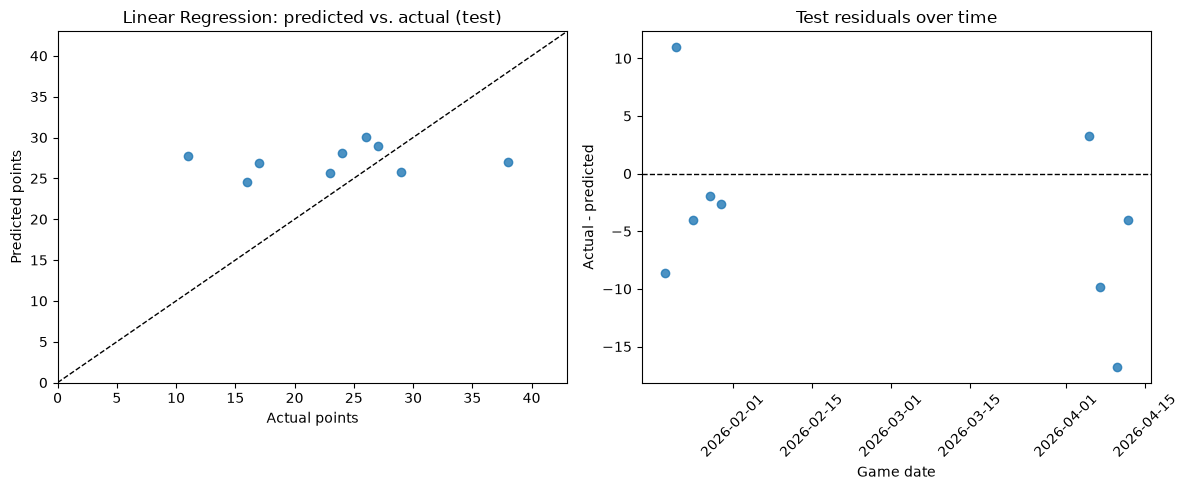

In [10]:
results = test[['player_id', 'game_date', TARGET]].assign(predicted=test_pred)
results['residual'] = results[TARGET] - results['predicted']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

lims = [0, max(results[TARGET].max(), results['predicted'].max()) + 5]
ax1.scatter(results[TARGET], results['predicted'], alpha=0.8)
ax1.plot(lims, lims, 'k--', linewidth=1)
ax1.set(xlim=lims, ylim=lims, xlabel='Actual points', ylabel='Predicted points',
        title='Linear Regression: predicted vs. actual (test)')

ax2.scatter(results['game_date'], results['residual'], alpha=0.8)
ax2.axhline(0, color='k', linestyle='--', linewidth=1)
ax2.set(xlabel='Game date', ylabel='Actual - predicted', title='Test residuals over time')
ax2.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

## Test error per player

With the sample there is only one player. On larger datasets, this table shows which players the model handles worst.

In [11]:
per_player = (
    results.groupby('player_id')
    .apply(lambda g: pd.Series({'n': len(g), **evaluate(g[TARGET], g['predicted'])}), include_groups=False)
    .astype({'n': int})
    .sort_values('MAE', ascending=False)
    .round(3)
)
per_player.head(20)

,n,MAE,RMSE,R2
player_id,,,,
201939,9,6.9,8.342,-0.218


## Notes

- The sample test split has only a few games, so these metrics are noisy. Re-run the notebook on the full dataset before drawing conclusions.
- Every feature is computed from earlier games only, and the train/test split is by date, so the test score is not inflated by leakage.
- To use a larger dataset, run `ml/EDA/feature_engineering.ipynb` on it, then point this notebook at the result with `POINTS_DATA_PATH=/path/to/features.csv`. Re-run `prediction_baseline.ipynb` on the same data so the comparison stays fair.
- To try more features, add their column names to `CONTEXT_FEATURES` in the Config cell, as long as they are known before the game.

## Save the model (optional)

Set `SAVE_MODEL = True` in the Config cell to write the fitted pipeline and its metrics to `ml/models/artifacts/`.

In [ ]:
if SAVE_MODEL:
    import joblib

    ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
    model_path = ARTIFACT_DIR / 'linear_regression_points.joblib'
    metrics_path = ARTIFACT_DIR / 'linear_regression_metrics.csv'
    joblib.dump({'pipeline': pipeline, 'features': FEATURES, 'target': TARGET}, model_path)
    lr_results.to_csv(metrics_path, index=False)
    print(f'Wrote {model_path} and {metrics_path}')
else:
    print('SAVE_MODEL is False; no files written')

SAVE_MODEL is False; no files written
